# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import HRSCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [5]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/hrscd/",
}
dataset = HRSCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 291


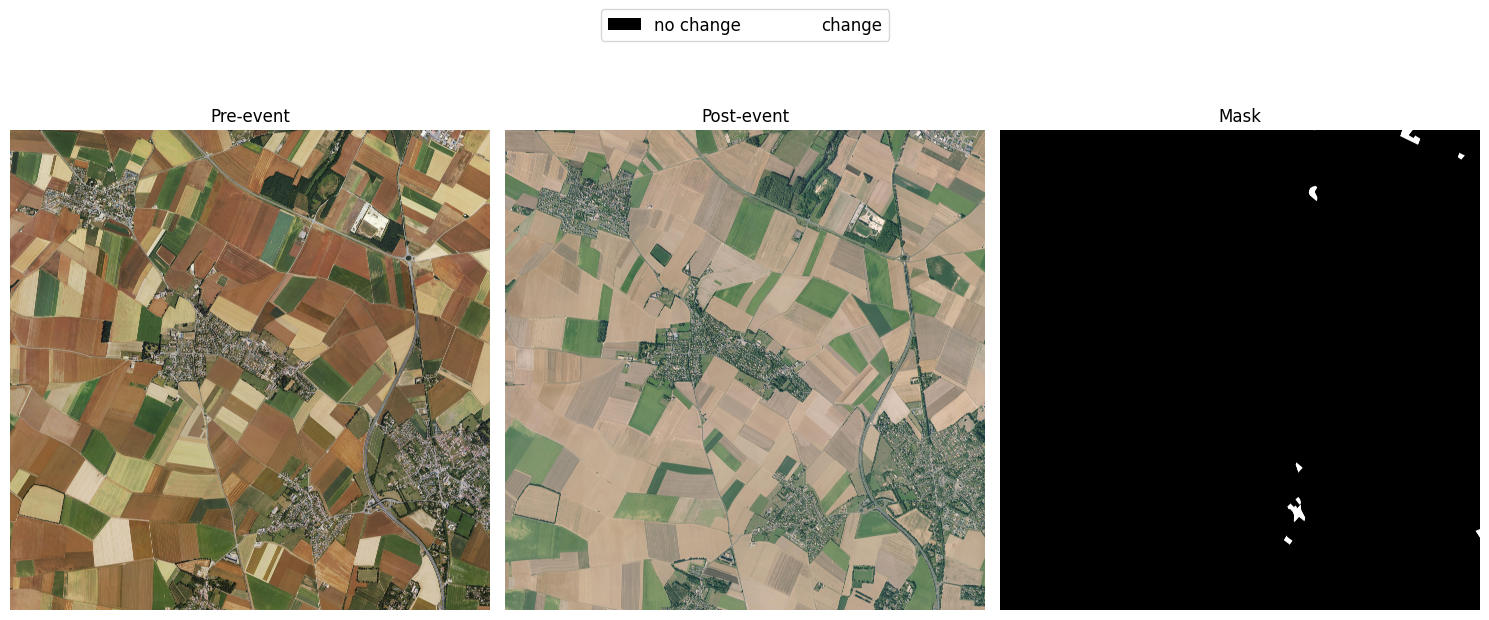

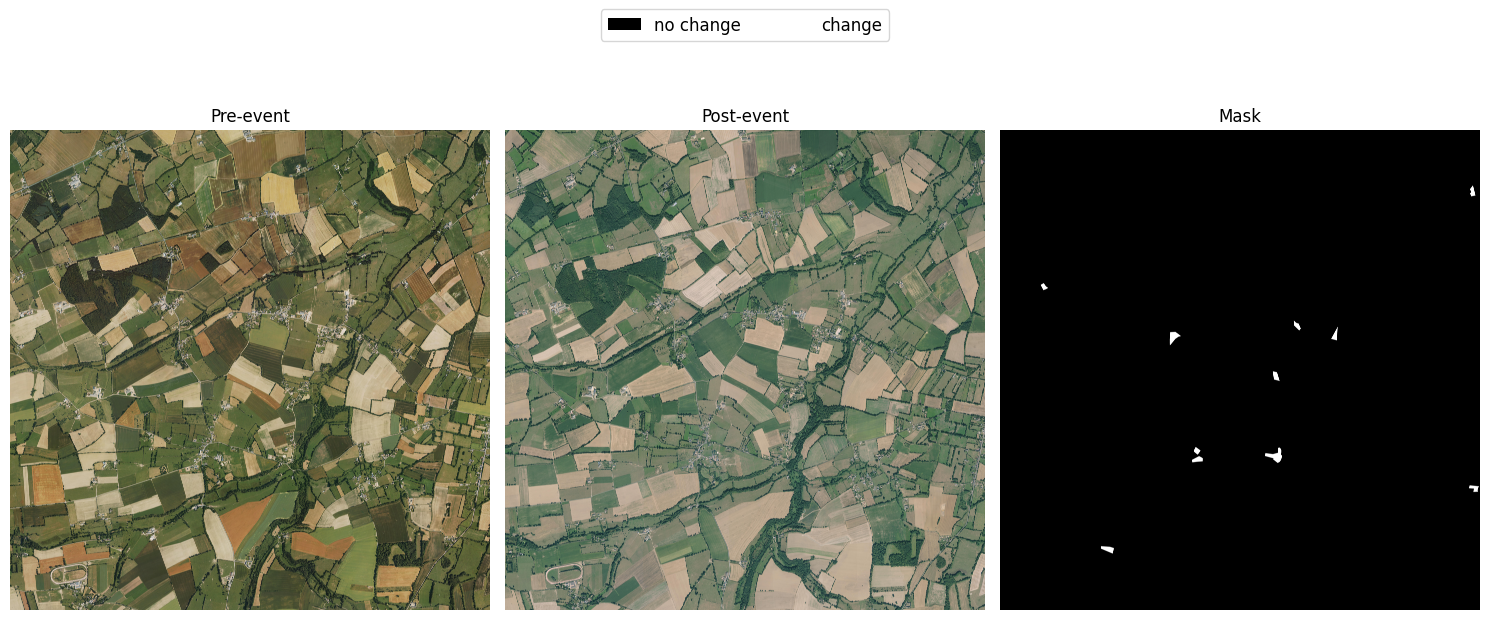

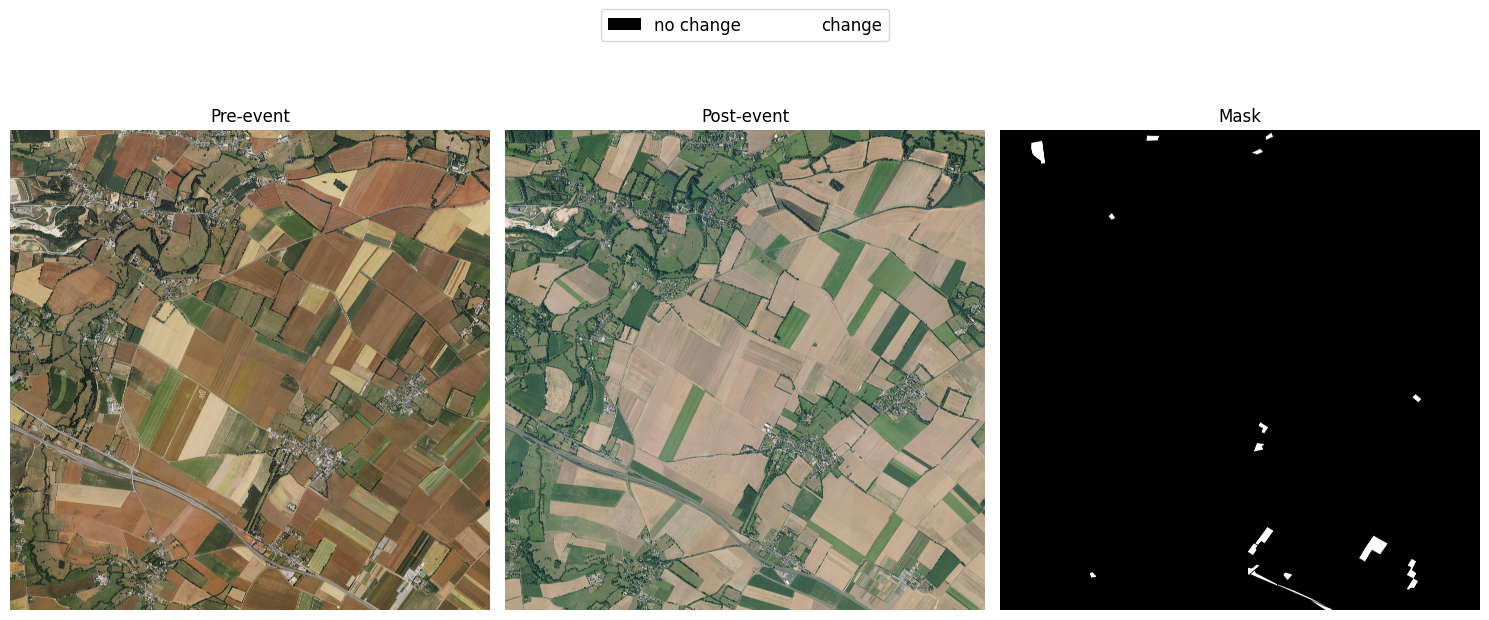

In [6]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [27]:
dataset.data_distribution_table()

,Number of pixels
no change,2.887653e+10
change,2.234685e+08


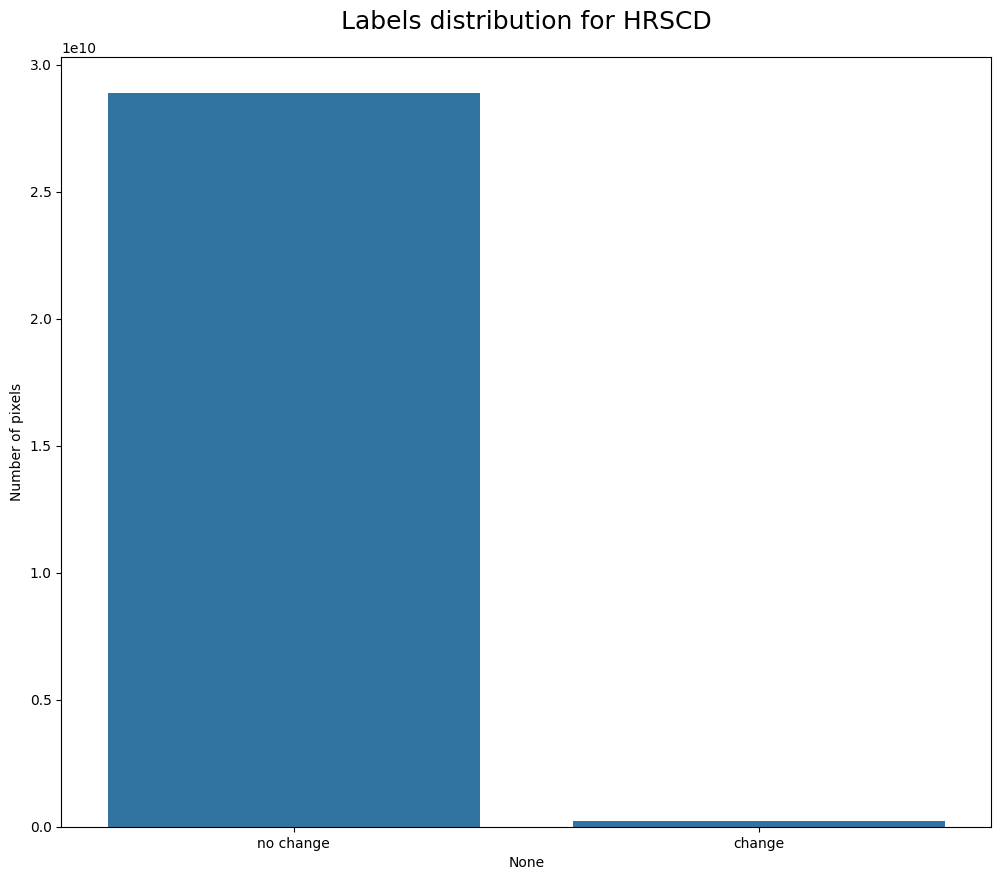

In [28]:
dataset.data_distribution_barchart();

## Load training and test data

In [5]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/hrscd/",
    "csv_file": "/home/dragik/data/FAIR_EO/hrscd/hrscd_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = HRSCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/hrscd/",
    "csv_file": "/home/dragik/data/FAIR_EO/hrscd/hrscd_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = HRSCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(175, 58)

## Create the model

In [6]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/hrscd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-28 15:20:52,214 INFO Starting training.
training: 100%|██████████| 11/11 [07:03<00:00, 38.48s/it]
2026-01-28 15:27:55,509 INFO epoch: 1, loss:  0.29955
testing on train set: 100%|██████████| 11/11 [06:59<00:00, 38.17s/it]
2026-01-28 15:34:56,622 INFO Accuracy:0.9891279820033482, Accuracy per Class:[0.9853738  0.99288217], Precision Micro:0.9815826113391093, Precision Macro:0.4943854360505352, Precision Weighted:0.9821274001623387, Precision per Class:[0.9853738  0.00339708], Recall Micro:0.9967073362178905, Recall Macro:0.5020141389889289, Recall Weighted:0.9967073362178904, Recall per Class:[1.         0.00402828], F1_score Micro:0.989087156848544, F1_score Macro:0.49815943572703975, F1_score Weighted:0.989363582155901, F1_score per Class:[0.99263302 0.00368585], IOU:0.9784099228229499, IOU mean:0.49361006182270006, IOU per Class:[0.9853738  0.00184633]
training: 100%|██████████| 11/11 [06:55<00:00, 37.77s/it]
2026-01-28 15:41:52,106 INFO epoch: 2, loss:  0.28939
testing on tr

## Predictions

2026-01-29 07:38:24,938 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/hrscd/checkpoint.pth.tar
2026-01-29 07:38:25,293 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/hrscd/checkpoint.pth.tar at epoch 21


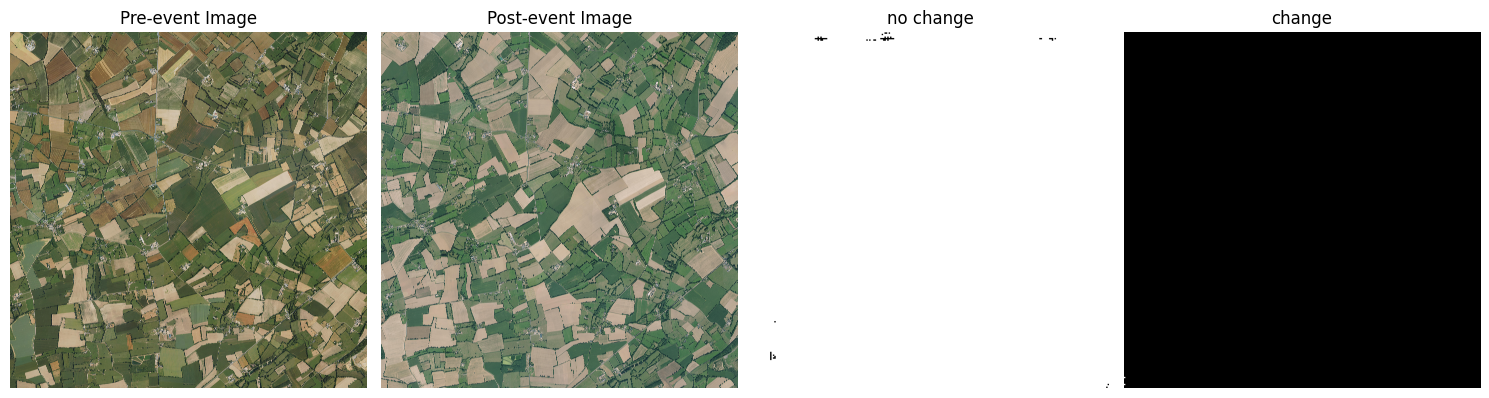

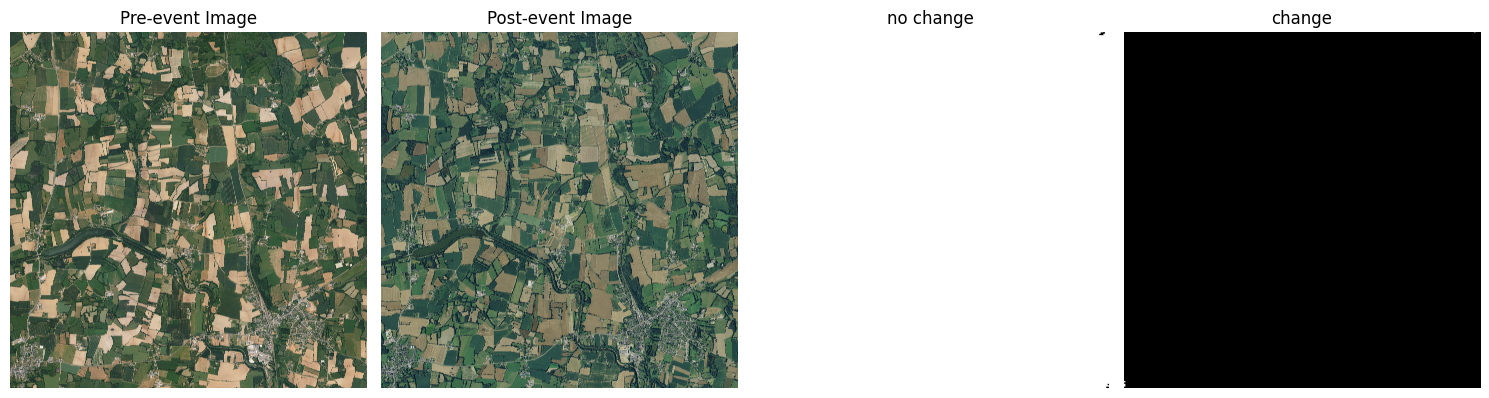

In [8]:
model_path = "/home/dragik/data/FAIR_EO/experiments/hrscd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("/home/dragik/data/FAIR_EO/hrscd/images_2006/2006/D14/14-2005-0420-6900-LA93.tif")
image2 = image_loader("/home/dragik/data/FAIR_EO/hrscd/images_2012/2012/D14/14-2012-0420-6900-LA93-0M50-E080.tif")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("/home/dragik/data/FAIR_EO/hrscd/images_2006/2006/D35/35-2006-0350-6815-LA93.tif")
image2 = image_loader("/home/dragik/data/FAIR_EO/hrscd/images_2012/2012/D35/35-2012-0350-6815-LA93-0M50-E080.tif")
fig = model.predict_masks(image1, image2, labels, transform)